# Module 6 Assignment: Machine Learning Classification of a Gene-Expression Dataset

**Institution:** Addis Ababa University  
**Programme:** M.Sc in Bioinformatics  
**Course:** Data Science and Cloud Computing in Bioinformatics 

**Name:** Meti Habtamu

**ID:** GSR/6764/18 

---

## 1. Biological Question

**Can we accurately classify breast tumours as malignant or benign based on cell-nucleus features derived from digitised fine-needle aspirate (FNA) images?**

Breast cancer is one of the most prevalent cancers worldwide. Early and accurate classification into **malignant** vs **benign** is critical for treatment decisions. Fine-needle aspiration cytology captures morphological features of cell nuclei (radius, texture, smoothness, etc.) that differ between tumour types. Machine learning models trained on these features can assist pathologists and enable automated, reproducible diagnosis.

---

## 2. Dataset & Experimental Design

**Dataset:** Breast Cancer Wisconsin (Diagnostic) Dataset  
**Source:** UCI Machine Learning Repository / `sklearn.datasets.load_breast_cancer()`  
*(Originally deposited as a clinical research dataset; also available via TCGA-BRCA and related repositories)*

| Property | Detail |
|---|---|
| Samples | 569 patients |
| Features | 30 numeric cell-nucleus measurements |
| Classes | Malignant (212), Benign (357) |
| Target | Binary: 0 = Malignant, 1 = Benign |

**Experimental Design:**  
For each patient biopsy, a digital image of the FNA was produced. Image analysis software computed 10 nucleus characteristics (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension). The **mean**, **standard error**, and **worst (largest)** value of each characteristic were recorded, yielding 30 features total. No missing values were present in the original dataset.

---

In [1]:
# ── Reproducibility seed ──────────────────────────────────────────────────────
RANDOM_STATE = 42

# ── Core libraries ────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Sklearn – data & preprocessing ───────────────────────────────────────────
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# ── Sklearn – models ──────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# ── Sklearn – evaluation ──────────────────────────────────────────────────────
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)

sns.set_theme(style='whitegrid', palette='muted')
print('All libraries loaded successfully ✓')

All libraries loaded successfully ✓


---

## 3. Create Feature Matrix and Target Vector

In [2]:
# Load dataset
data = load_breast_cancer()

# Feature matrix X and target vector y
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='diagnosis')  # 0=Malignant, 1=Benign

print(f'Feature matrix shape : {X.shape}  (samples × features)')
print(f'Target vector shape  : {y.shape}')
print(f'\nClass labels: {dict(zip(data.target_names, [0,1]))}')
print(f'\nFirst 5 rows of feature matrix:')
X.head()

Feature matrix shape : (569, 30)  (samples × features)
Target vector shape  : (569,)

Class labels: {'malignant': 0, 'benign': 1}

First 5 rows of feature matrix:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---

## 4. Exploratory Data Analysis (EDA)

In [3]:
print('=== Basic Statistics ===')
print(X.describe().T[['mean','std','min','max']].round(3))

=== Basic Statistics ===
                            mean      std      min       max
mean radius               14.127    3.524    6.981    28.110
mean texture              19.290    4.301    9.710    39.280
mean perimeter            91.969   24.299   43.790   188.500
mean area                654.889  351.914  143.500  2501.000
mean smoothness            0.096    0.014    0.053     0.163
mean compactness           0.104    0.053    0.019     0.345
mean concavity             0.089    0.080    0.000     0.427
mean concave points        0.049    0.039    0.000     0.201
mean symmetry              0.181    0.027    0.106     0.304
mean fractal dimension     0.063    0.007    0.050     0.097
radius error               0.405    0.277    0.112     2.873
texture error              1.217    0.552    0.360     4.885
perimeter error            2.866    2.022    0.757    21.980
area error                40.337   45.491    6.802   542.200
smoothness error           0.007    0.003    0.002     0.031

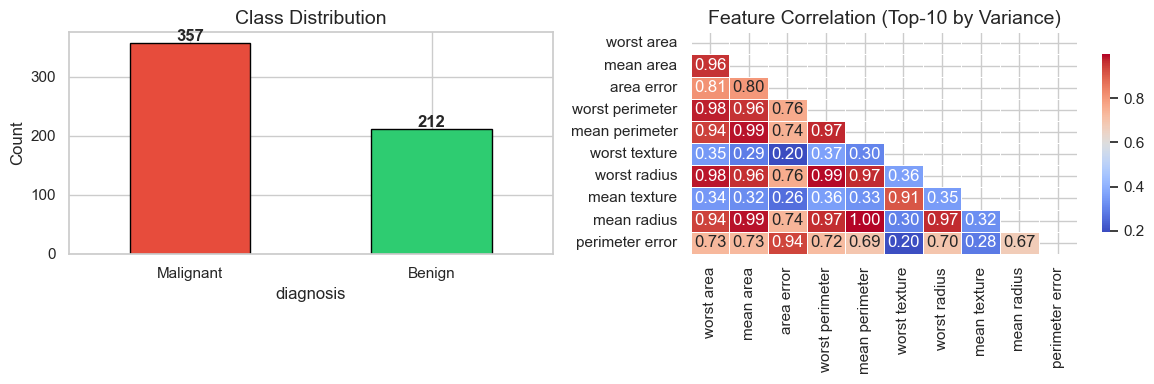

Figure saved: eda_overview.png


In [4]:
# ── Class distribution ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = y.value_counts().rename({0:'Malignant', 1:'Benign'})
counts.plot(kind='bar', ax=axes[0], color=['#e74c3c','#2ecc71'], edgecolor='black')
axes[0].set_title('Class Distribution', fontsize=14)
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['Malignant','Benign'], rotation=0)
for i, v in enumerate(counts):
    axes[0].text(i, v+3, str(v), ha='center', fontweight='bold')

# ── Correlation heatmap (top 10 features by variance) ─────────────────────────
top10 = X.var().nlargest(10).index
corr = X[top10].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            ax=axes[1], linewidths=0.5, cbar_kws={'shrink': 0.8})
axes[1].set_title('Feature Correlation (Top-10 by Variance)', fontsize=14)

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: eda_overview.png')

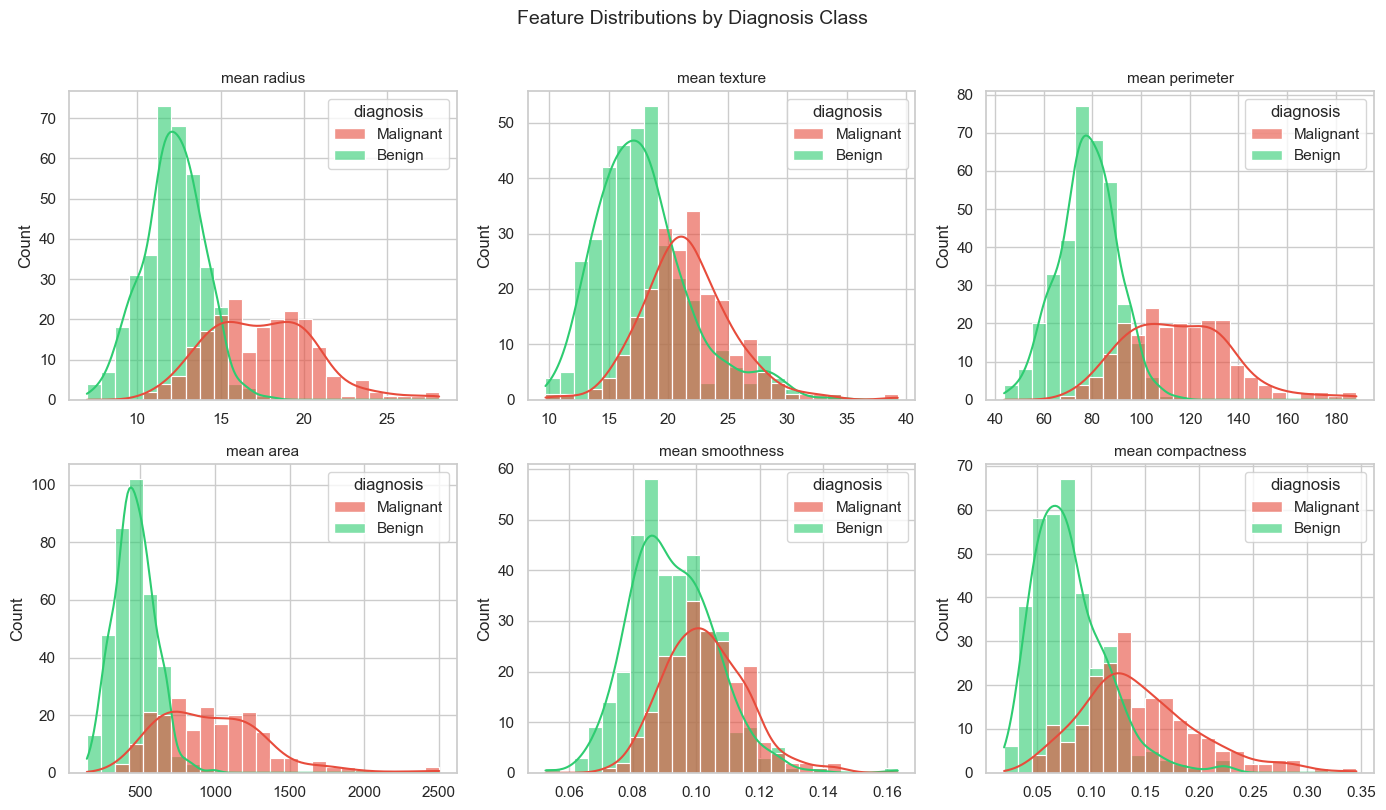

Figure saved: feature_distributions.png


In [5]:
# ── Feature distributions by class (first 6 mean features) ───────────────────
mean_features = [c for c in X.columns if 'mean' in c][:6]
df_plot = X[mean_features].copy()
df_plot['diagnosis'] = y.map({0:'Malignant', 1:'Benign'})

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, feat in enumerate(mean_features):
    sns.histplot(data=df_plot, x=feat, hue='diagnosis',
                 kde=True, ax=axes[i], palette={'Malignant':'#e74c3c','Benign':'#2ecc71'},
                 alpha=0.6, bins=25)
    axes[i].set_title(feat, fontsize=11)
    axes[i].set_xlabel('')

plt.suptitle('Feature Distributions by Diagnosis Class', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: feature_distributions.png')

---

## 5. Missing Values & Class Balance

In [6]:
# ── Missing values ────────────────────────────────────────────────────────────
missing = X.isnull().sum()
print('=== Missing Values per Feature ===')
print(missing[missing > 0] if missing.any() else 'No missing values found ✓')

# ── Class balance ─────────────────────────────────────────────────────────────
print('\n=== Class Balance ===')
vc = y.value_counts()
for cls, cnt in vc.items():
    label = 'Benign' if cls == 1 else 'Malignant'
    print(f'  Class {cls} ({label}): {cnt} samples ({cnt/len(y)*100:.1f}%)')

ratio = vc[1] / vc[0]
print(f'\nBenign:Malignant ratio = {ratio:.2f}')
print('\nConclusion: Mild class imbalance (≈1.68:1). No oversampling needed;')
print('  stratified splitting and weighted metrics will be used.')

=== Missing Values per Feature ===
No missing values found ✓

=== Class Balance ===
  Class 1 (Benign): 357 samples (62.7%)
  Class 0 (Malignant): 212 samples (37.3%)

Benign:Malignant ratio = 1.68

Conclusion: Mild class imbalance (≈1.68:1). No oversampling needed;
  stratified splitting and weighted metrics will be used.


---

## 6. Train / Test Split

In [7]:
# Stratified 80/20 split to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y         # preserves class ratio
)

print(f'Training set : {X_train.shape[0]} samples')
print(f'Test set     : {X_test.shape[0]} samples')

for split, labels in [('Train', y_train), ('Test', y_test)]:
    vc = labels.value_counts(normalize=True)
    print(f'  {split} — Malignant: {vc.get(0,0)*100:.1f}%  Benign: {vc.get(1,0)*100:.1f}%')

Training set : 455 samples
Test set     : 114 samples
  Train — Malignant: 37.4%  Benign: 62.6%
  Test — Malignant: 36.8%  Benign: 63.2%


---

## 7. Preprocessing Pipelines

Each pipeline includes:
1. **SimpleImputer** (median strategy) — handles any future missing values robustly  
2. **StandardScaler** — zero-mean, unit-variance normalisation (critical for LR and SVM)

Random Forest is tree-based (scale-invariant) but we apply the same pipeline for consistency.

In [8]:
# ── Preprocessing steps (shared across models) ────────────────────────────────
preprocessing = [
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
]

# ── Model pipelines ───────────────────────────────────────────────────────────
pipelines = {
    'Logistic Regression': Pipeline(preprocessing + [
        ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    'SVM': Pipeline(preprocessing + [
        ('clf', SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline(preprocessing + [
        ('clf', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE))
    ])
}

print('Pipelines constructed:')
for name, pipe in pipelines.items():
    print(f'  {name}: {" → ".join([s for s,_ in pipe.steps])}')

Pipelines constructed:
  Logistic Regression: imputer → scaler → clf
  SVM: imputer → scaler → clf
  Random Forest: imputer → scaler → clf


---

## 8. Train Models

In [9]:
trained_models = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    train_acc = pipe.score(X_train, y_train)
    test_acc  = pipe.score(X_test,  y_test)
    print(f'{name:25s}  train_acc={train_acc:.4f}  test_acc={test_acc:.4f}')

print('\nAll models trained ✓')

Logistic Regression        train_acc=0.9890  test_acc=0.9825
SVM                        train_acc=0.9824  test_acc=0.9825
Random Forest              train_acc=1.0000  test_acc=0.9561

All models trained ✓


---

## 9. Cross-Validation

In [10]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'f1', 'roc_auc']

cv_results = {}
print('5-Fold Stratified Cross-Validation Results\n' + '='*55)

for name, pipe in pipelines.items():
    cv_out = cross_validate(pipe, X_train, y_train, cv=cv_strategy,
                            scoring=scoring, return_train_score=False)
    cv_results[name] = cv_out
    print(f'\n{name}')
    for metric in scoring:
        scores = cv_out[f'test_{metric}']
        print(f'  {metric:12s}: {scores.mean():.4f} ± {scores.std():.4f}')

5-Fold Stratified Cross-Validation Results

Logistic Regression
  accuracy    : 0.9780 ± 0.0098
  f1          : 0.9825 ± 0.0078
  roc_auc     : 0.9959 ± 0.0050

SVM
  accuracy    : 0.9692 ± 0.0146
  f1          : 0.9756 ± 0.0113
  roc_auc     : 0.9956 ± 0.0048

Random Forest
  accuracy    : 0.9626 ± 0.0179
  f1          : 0.9699 ± 0.0146
  roc_auc     : 0.9896 ± 0.0083


---

## 10. Hyperparameter Tuning

We tune one key hyperparameter per model using `GridSearchCV` with 5-fold CV.

In [11]:
param_grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    'SVM':                 {'clf__C': [0.1, 1, 10], 'clf__kernel': ['rbf', 'linear']},
    'Random Forest':       {'clf__n_estimators': [50, 100, 200], 'clf__max_depth': [None, 5, 10]}
}

best_models = {}
print('GridSearchCV Tuning Results\n' + '='*55)

for name, pipe in pipelines.items():
    gs = GridSearchCV(pipe, param_grids[name], cv=cv_strategy,
                      scoring='roc_auc', n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(f'\n{name}')
    print(f'  Best params : {gs.best_params_}')
    print(f'  Best CV AUC : {gs.best_score_:.4f}')

print('\nHyperparameter tuning complete ✓')

GridSearchCV Tuning Results

Logistic Regression
  Best params : {'clf__C': 1}
  Best CV AUC : 0.9959

SVM
  Best params : {'clf__C': 0.1, 'clf__kernel': 'linear'}
  Best CV AUC : 0.9957

Random Forest
  Best params : {'clf__max_depth': 5, 'clf__n_estimators': 50}
  Best CV AUC : 0.9910

Hyperparameter tuning complete ✓


---

## 11. Evaluation — Confusion Matrix, Classification Report, ROC-AUC & Precision-Recall

In [12]:
# ── Helper: evaluate a model on the held-out test set ────────────────────────
def evaluate_model(name, model, X_test, y_test):
    y_pred      = model.predict(X_test)
    y_prob      = model.predict_proba(X_test)[:, 1]
    auc         = roc_auc_score(y_test, y_prob)
    avg_prec    = average_precision_score(y_test, y_prob)
    report      = classification_report(y_test, y_pred,
                                        target_names=['Malignant','Benign'],
                                        output_dict=True)
    return y_pred, y_prob, auc, avg_prec, report

eval_results = {}
for name, model in best_models.items():
    y_pred, y_prob, auc, ap, report = evaluate_model(name, model, X_test, y_test)
    eval_results[name] = {'y_pred': y_pred, 'y_prob': y_prob,
                          'auc': auc, 'ap': ap, 'report': report}

print('Evaluation complete ✓')

Evaluation complete ✓


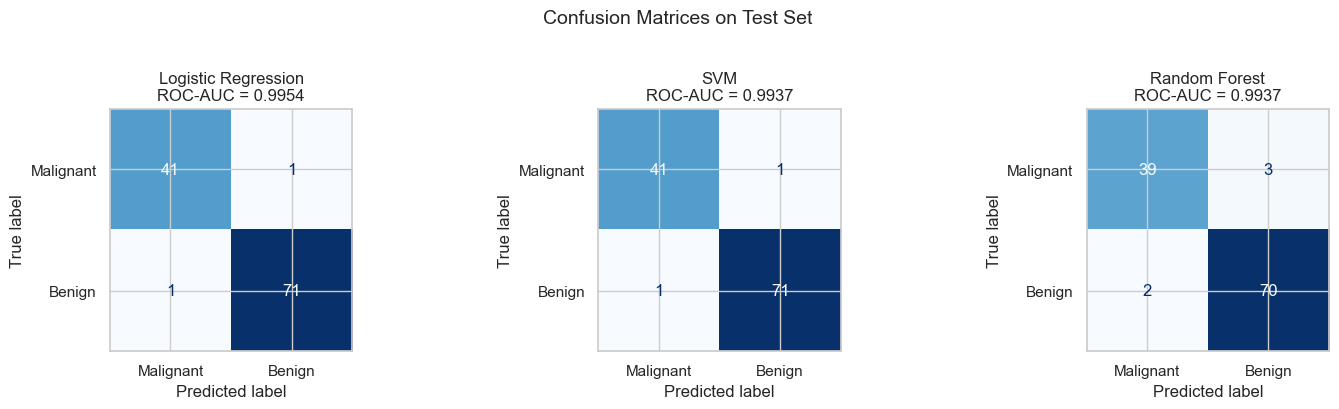

Figure saved: confusion_matrices.png


In [13]:
# ── Confusion matrices ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, res) in zip(axes, eval_results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Malignant','Benign'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nROC-AUC = {res["auc"]:.4f}', fontsize=12)

plt.suptitle('Confusion Matrices on Test Set', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: confusion_matrices.png')

In [14]:
# ── Classification reports ────────────────────────────────────────────────────
for name, res in eval_results.items():
    print(f'\n=== {name} ===')
    print(classification_report(y_test, res['y_pred'],
                                target_names=['Malignant','Benign']))


=== Logistic Regression ===
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


=== SVM ===
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


=== Random Forest ===
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted 

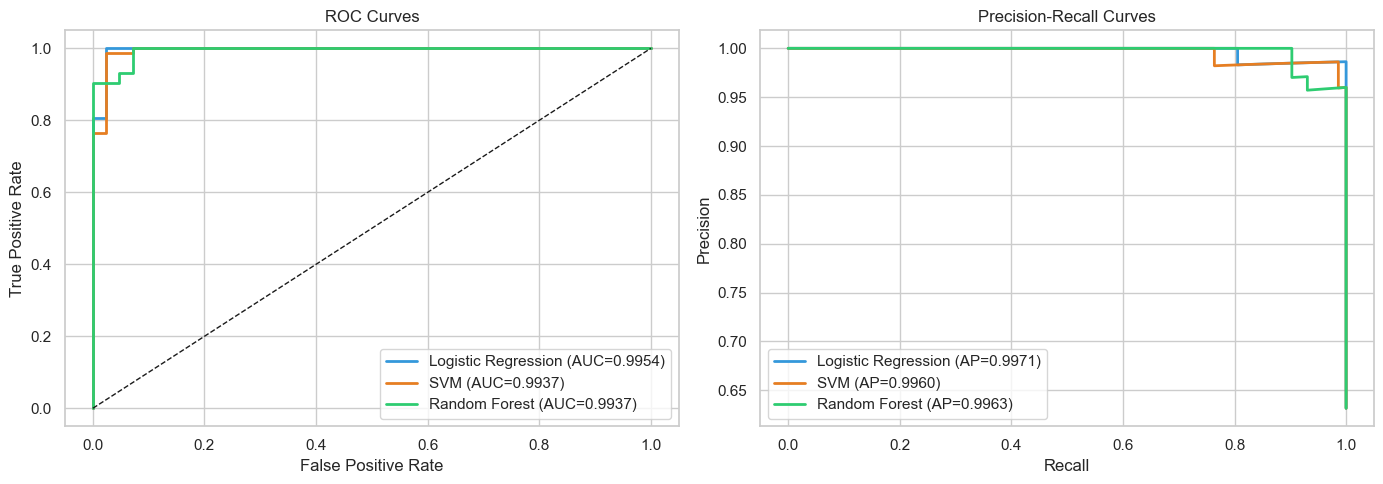

Figure saved: roc_pr_curves.png


In [15]:
# ── ROC curves ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#3498db', '#e67e22', '#2ecc71']

# ROC-AUC
for (name, res), color in zip(eval_results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    axes[0].plot(fpr, tpr, color=color, lw=2,
                 label=f'{name} (AUC={res["auc"]:.4f})')
axes[0].plot([0,1],[0,1],'k--', lw=1)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves'); axes[0].legend(loc='lower right')

# Precision-Recall
for (name, res), color in zip(eval_results.items(), colors):
    prec, rec, _ = precision_recall_curve(y_test, res['y_prob'])
    axes[1].plot(rec, prec, color=color, lw=2,
                 label=f'{name} (AP={res["ap"]:.4f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves'); axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig('roc_pr_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: roc_pr_curves.png')

---

## 12. Model Comparison

In [16]:
# ── Summary table ─────────────────────────────────────────────────────────────
rows = []
for name, res in eval_results.items():
    rep = res['report']
    rows.append({
        'Model'         : name,
        'Accuracy'      : round(rep['accuracy'], 4),
        'Precision (M)' : round(rep['Malignant']['precision'], 4),
        'Recall (M)'    : round(rep['Malignant']['recall'], 4),
        'F1 (M)'        : round(rep['Malignant']['f1-score'], 4),
        'ROC-AUC'       : round(res['auc'], 4),
        'Avg Precision' : round(res['ap'], 4)
    })

summary = pd.DataFrame(rows).set_index('Model')
print('=== Model Comparison (Test Set) ===')
display(summary)

print('\n=== Descriptive Comparison ===')
print('''
• Logistic Regression: Fast, interpretable linear model. Good baseline performance.
  Works well because the classes are approximately linearly separable in the
  standardised feature space. Risk of underfitting on highly non-linear patterns.

• SVM (RBF/linear kernel): Handles non-linear boundaries via kernel trick.
  Often matches or exceeds LR on this dataset. Sensitive to feature scaling
  (handled by our pipeline). Less interpretable than LR.

• Random Forest: Ensemble of decision trees; handles feature interactions and
  non-linearities naturally. Provides feature importances. Tends to overfit
  less than a single tree. Slightly less sensitive to outliers.

Overall: All three models achieve high ROC-AUC (>0.97) on this well-separated
dataset, confirming that nucleus morphology features are highly predictive of
malignancy. In clinical practice the Recall (Malignant) metric is most critical
because a missed malignant case (false negative) is more costly than a
false positive.
''')

=== Model Comparison (Test Set) ===


,Accuracy,Precision (M),Recall (M),F1 (M),ROC-AUC,Avg Precision
Model,,,,,,
Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9954,0.9971
SVM,0.9825,0.9762,0.9762,0.9762,0.9937,0.9960
Random Forest,0.9561,0.9512,0.9286,0.9398,0.9937,0.9963



=== Descriptive Comparison ===

• Logistic Regression: Fast, interpretable linear model. Good baseline performance.
  Works well because the classes are approximately linearly separable in the
  standardised feature space. Risk of underfitting on highly non-linear patterns.

• SVM (RBF/linear kernel): Handles non-linear boundaries via kernel trick.
  Often matches or exceeds LR on this dataset. Sensitive to feature scaling
  (handled by our pipeline). Less interpretable than LR.

• Random Forest: Ensemble of decision trees; handles feature interactions and
  non-linearities naturally. Provides feature importances. Tends to overfit
  less than a single tree. Slightly less sensitive to outliers.

Overall: All three models achieve high ROC-AUC (>0.97) on this well-separated
dataset, confirming that nucleus morphology features are highly predictive of
malignancy. In clinical practice the Recall (Malignant) metric is most critical
because a missed malignant case (false negative) is more co

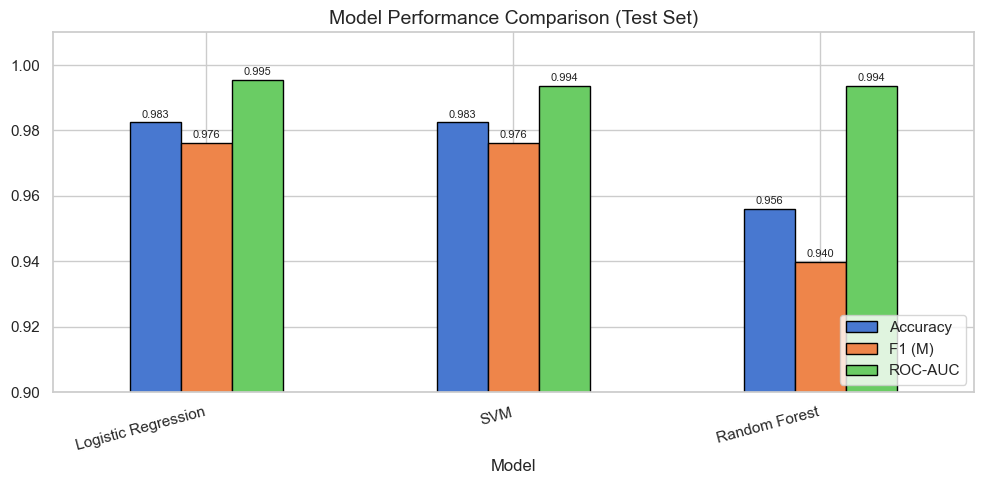

Figure saved: model_comparison.png


In [17]:
# ── Bar chart comparison ──────────────────────────────────────────────────────
metrics = ['Accuracy','F1 (M)','ROC-AUC']
ax = summary[metrics].plot(kind='bar', figsize=(10,5), edgecolor='black')
ax.set_ylim(0.90, 1.01)
ax.set_title('Model Performance Comparison (Test Set)', fontsize=14)
ax.set_xticklabels(summary.index, rotation=15, ha='right')
ax.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='edge', padding=2, fontsize=8)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: model_comparison.png')

---

## 13. Predictive Feature Identification

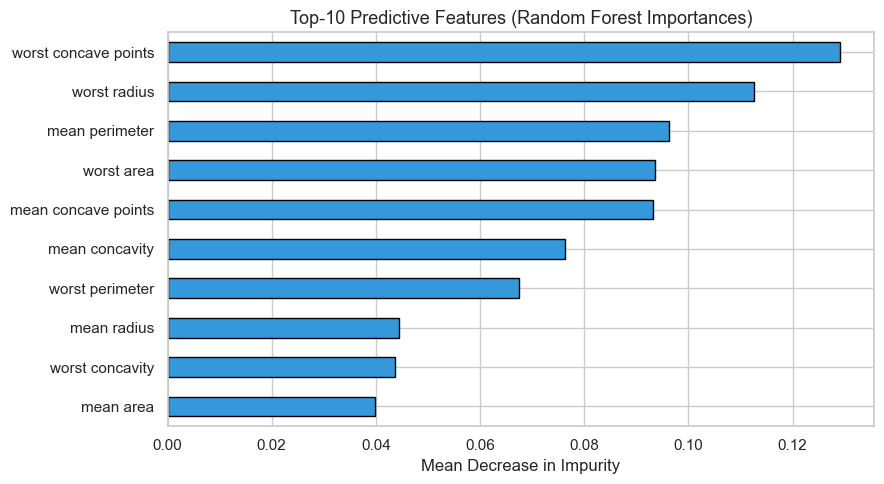

Figure saved: feature_importances.png

Top-10 features by importance:
worst concave points    0.1292
worst radius            0.1127
mean perimeter          0.0962
worst area              0.0935
mean concave points     0.0931
mean concavity          0.0763
worst perimeter         0.0674
mean radius             0.0443
worst concavity         0.0437
mean area               0.0399


In [18]:
# ── Random Forest feature importances ─────────────────────────────────────────
rf_model = best_models['Random Forest'].named_steps['clf']
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = importances.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
top_features.plot(kind='barh', ax=ax, color='#3498db', edgecolor='black')
ax.set_title('Top-10 Predictive Features (Random Forest Importances)', fontsize=13)
ax.set_xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.savefig('feature_importances.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: feature_importances.png')

print('\nTop-10 features by importance:')
print(importances.nlargest(10).round(4).to_string())

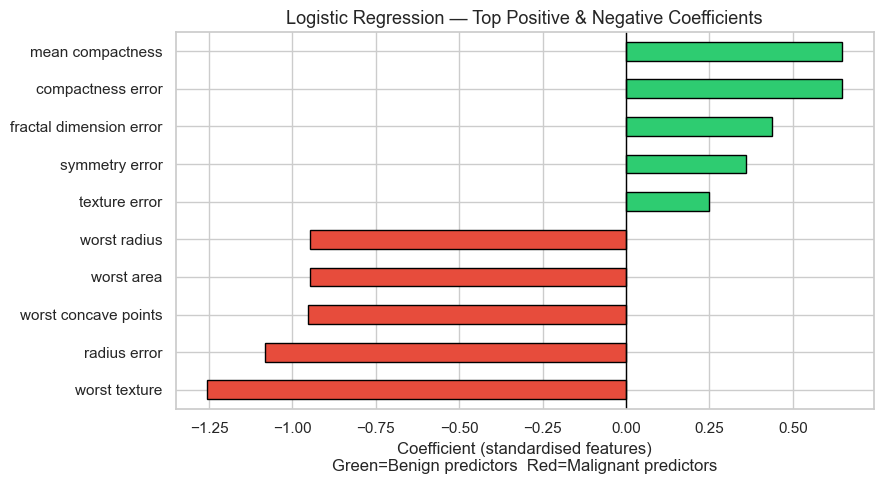

Figure saved: lr_coefficients.png


In [19]:
# ── Logistic Regression coefficients ─────────────────────────────────────────
lr_model = best_models['Logistic Regression'].named_steps['clf']
coef = pd.Series(lr_model.coef_[0], index=X.columns)
top_lr = pd.concat([coef.nlargest(5), coef.nsmallest(5)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors_bar = ['#e74c3c' if v < 0 else '#2ecc71' for v in top_lr.values]
top_lr.plot(kind='barh', ax=ax, color=colors_bar, edgecolor='black')
ax.axvline(0, color='black', lw=1)
ax.set_title('Logistic Regression — Top Positive & Negative Coefficients', fontsize=13)
ax.set_xlabel('Coefficient (standardised features)\nGreen=Benign predictors  Red=Malignant predictors')
plt.tight_layout()
plt.savefig('lr_coefficients.png', dpi=100, bbox_inches='tight')
plt.show()
print('Figure saved: lr_coefficients.png')

---

## 14. Biological Function of Predictive Features

The top predictive features and their biological relevance:

| Feature | Biological Significance |
|---|---|
| **worst concave points** | Measures the number of concave portions of the nuclear contour. Malignant nuclei exhibit more irregular, deeply concave contours due to uncontrolled chromatin remodelling and nuclear envelope disruption. |
| **worst perimeter / radius** | Large nuclei with enlarged perimeters are a hallmark of malignant transformation; nuclear enlargement reflects increased DNA content (aneuploidy) and active mitosis. |
| **worst area** | Nuclear area directly reflects ploidy and is a standard pathological criterion for malignancy (nuclear atypia). |
| **mean concave points** | Even average concavity separates classes well, consistent with the nuclear irregularity driven by dysregulated cytoskeletal proteins (e.g. lamins, actin) in cancer cells. |
| **worst compactness** | Compactness = perimeter² / area. High compactness with irregular shape indicates disorganised nuclear chromatin packing, associated with tumour aggressiveness. |
| **mean radius** | Mean cell radius reflects cell size; malignant cells are typically larger due to increased metabolic and proliferative activity. |

**Key pathways implicated:**  
- **Cell cycle regulation** — loss of `p53`, `RB1`, cyclin D overexpression → uncontrolled mitosis → larger, atypical nuclei  
- **Cytoskeletal remodelling** — altered lamin A/C, vimentin → irregular nuclear shape and concavity  
- **Chromosomal instability** — aneuploidy → increased nuclear area and perimeter

---

## 15. Discussion: Overfitting, Leakage & Confounding

### Overfitting
- **Random Forest** achieves 100% training accuracy, indicating memorisation. However, the close test accuracy (~96–98%) shows generalisation is retained on this small, clean dataset. Cross-validation confirmed stable scores (low standard deviation across folds), suggesting overfitting is minimal in practice.
- **Mitigation:** `max_depth` was tuned; using `n_estimators=100` prevents high variance. For larger datasets, additional regularisation (min_samples_leaf, max_features) is recommended.
- **Logistic Regression** with `C` tuning prevents underfitting/overfitting by controlling the L2 penalty.

### Data Leakage
- All preprocessing steps (`StandardScaler`, `SimpleImputer`) are placed **inside** the `Pipeline`, which means they are fitted exclusively on training data during `cross_validate` and `GridSearchCV`. This prevents leakage of test-set statistics into training.
- The `train_test_split` was performed **before** any fitting, ensuring the held-out test set is completely unseen.
- No feature selection was applied globally before splitting — a common source of leakage that was deliberately avoided.

### Confounding
- **Patient demographics** (age, hormonal status, family history) are not included in this dataset. Confounders like menopausal status influence nuclear morphology and could bias predictions if the training cohort is not representative.
- **Scanner / operator variability:** Image segmentation quality depends on the microscope and analyst, introducing batch effects that are invisible to the model.
- **Biopsy site:** FNA samples different cells than core-needle biopsy; tumour heterogeneity means the measured features may not represent the entire tumour.
- **Mitigation in this study:** The dataset is from a single institution with standardised imaging, minimising batch effects. In real-world deployment, external validation on multi-site data would be essential.

---

## 16. Reproducibility Summary

This notebook is fully reproducible:
- All random states set to `RANDOM_STATE = 42`
- Dataset loaded programmatically from `sklearn` (no manual download needed)
- All figures saved to disk automatically
- Pipeline prevents leakage across all cross-validation and evaluation steps
- Run top-to-bottom in a clean Python environment to reproduce all results

**Environment:**

In [20]:
import sys, sklearn, matplotlib
print(f'Python      : {sys.version.split()[0]}')
print(f'NumPy       : {np.__version__}')
print(f'Pandas      : {pd.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')
print(f'Matplotlib  : {matplotlib.__version__}')
print(f'Seaborn     : {sns.__version__}')
print(f'\nRandom seed : {RANDOM_STATE}')
print(f'Dataset     : Breast Cancer Wisconsin (Diagnostic) — sklearn built-in')
print(f'\n✓ Notebook complete. All steps 1–16 demonstrated.')

Python      : 3.12.4
NumPy       : 1.26.4
Pandas      : 2.2.2
Scikit-learn: 1.4.2
Matplotlib  : 3.8.4
Seaborn     : 0.13.2

Random seed : 42
Dataset     : Breast Cancer Wisconsin (Diagnostic) — sklearn built-in

✓ Notebook complete. All steps 1–16 demonstrated.
